# Name: Tushar Singh
# Rol No. 2501940055
# Course: MCA(AI &ML)

#### Lab 1 — Variational Autoencoder (VAE) for MNIST Image Generation


In [ ]:
import os, random, numpy as np, matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUT = "lab1_outputs"
os.makedirs(OUT, exist_ok=True)
print("PyTorch:", torch.__version__)
print("Device:", device)

PyTorch: 2.14.1+cpu
Device: cpu


## 1. Load and inspect the MNIST dataset

100%|██████████| 9.91M/9.91M [00:00<00:00, 38.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.03MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 5.10MB/s]


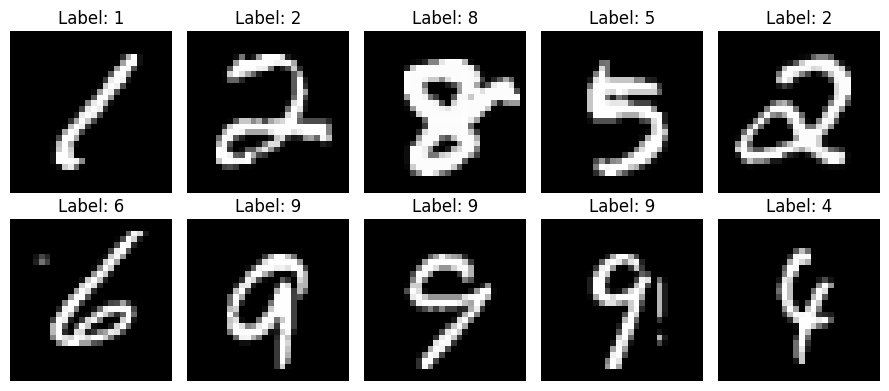

In [ ]:
transform = transforms.ToTensor()
train_ds = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_ds  = datasets.MNIST(root="data", train=False, download=True, transform=transform)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=torch.cuda.is_available())
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=2, pin_memory=torch.cuda.is_available())

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(2, 5, figsize=(9, 4))
for ax, image, label in zip(axes.flat, images[:10], labels[:10]):
    ax.imshow(image.squeeze(), cmap="gray"); ax.set_title(f"Label: {label.item()}"); ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()
        self.encoder = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU())
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )
    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + torch.randn_like(std) * std
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

model = VAE(latent_dim=2).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
x = next(iter(train_loader))[0].to(device)
recon, mu, logvar = model(x)
print("Input:", tuple(x.shape), "| Reconstruction:", tuple(recon.shape), "| Latent:", tuple(mu.shape))

Input: (128, 1, 28, 28) | Reconstruction: (128, 784) | Latent: (128, 2)


In [ ]:
EPOCHS = 5  # Increase to 10–20 for a longer experiment if time permits.
history = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_loss = total_recon = total_kl = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        recon, mu, logvar = model(x)
        recon_loss = F.binary_cross_entropy(recon, x.flatten(1), reduction="sum")
        kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
        loss = (recon_loss + kl_loss) / x.size(0)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()
    row = {"epoch": epoch, "total": total_loss / len(train_ds),
           "reconstruction": total_recon / len(train_ds), "kl": total_kl / len(train_ds)}
    history.append(row)
    print(f"Epoch {epoch}/{EPOCHS} | Total: {row['total']:.4f} | Recon: {row['reconstruction']:.4f} | KL: {row['kl']:.4f}")

torch.save(model.state_dict(), os.path.join(OUT, "vae_mnist.pt"))
print("Saved model.")

Epoch 1/5 | Total: 194.9713 | Recon: 187.9996 | KL: 6.9717
Epoch 2/5 | Total: 169.7435 | Recon: 164.4344 | KL: 5.3091
Epoch 3/5 | Total: 165.0642 | Recon: 159.7517 | KL: 5.3125
Epoch 4/5 | Total: 162.7546 | Recon: 157.4121 | KL: 5.3425
Epoch 5/5 | Total: 161.2249 | Recon: 155.8487 | KL: 5.3762
Saved model.


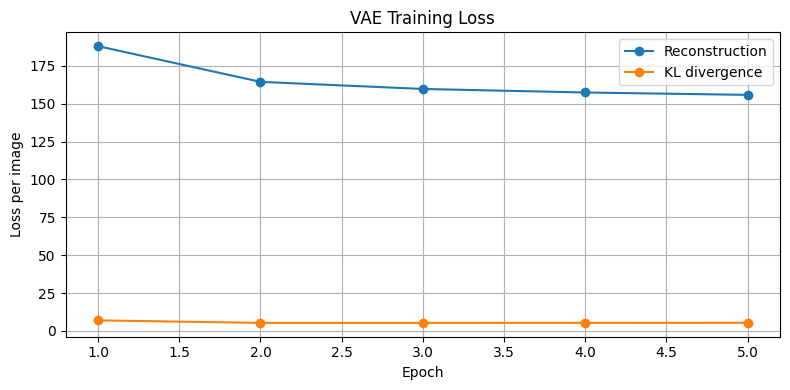

In [ ]:
epochs = [r["epoch"] for r in history]
plt.figure(figsize=(8,4))
plt.plot(epochs, [r["reconstruction"] for r in history], marker="o", label="Reconstruction")
plt.plot(epochs, [r["kl"] for r in history], marker="o", label="KL divergence")
plt.xlabel("Epoch"); plt.ylabel("Loss per image"); plt.title("VAE Training Loss")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(os.path.join(OUT, "training_losses.png")); plt.show()

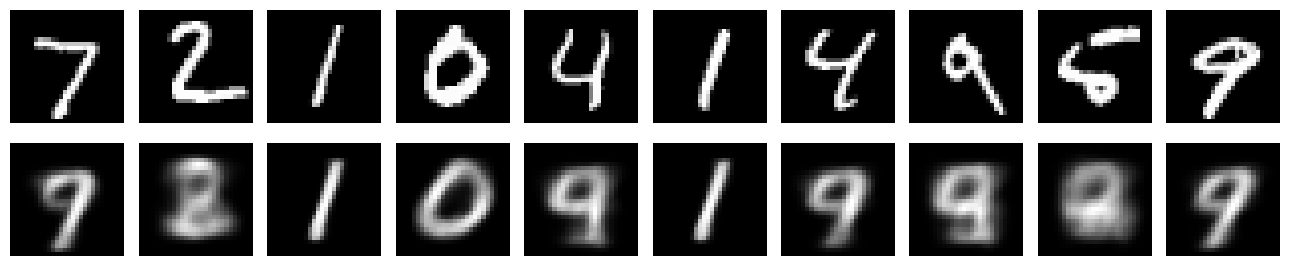

In [ ]:
model.eval()
x, _ = next(iter(test_loader))
x_device = x.to(device)
with torch.no_grad():
    reconstructed, _, _ = model(x_device)
reconstructed = reconstructed.cpu().view(-1, 1, 28, 28)
fig, axes = plt.subplots(2, 10, figsize=(13, 3))
for i in range(10):
    axes[0, i].imshow(x[i].squeeze(), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(reconstructed[i].squeeze(), cmap="gray"); axes[1, i].axis("off")
axes[0,0].set_ylabel("Original"); axes[1,0].set_ylabel("Reconstructed")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "reconstructed_images.png")); plt.show()

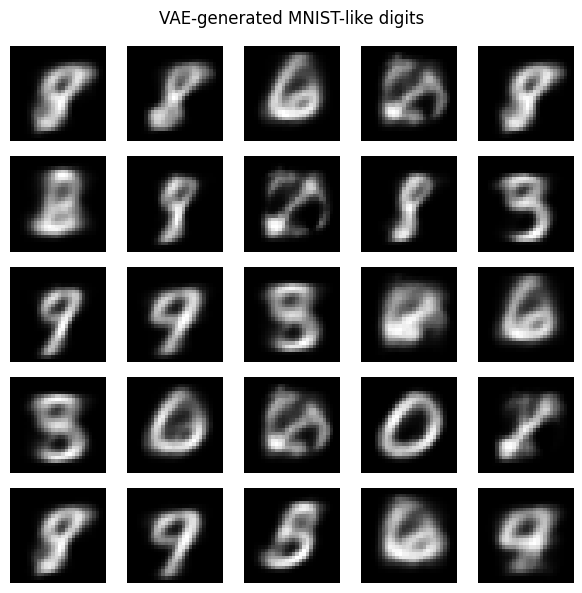

In [ ]:
with torch.no_grad():
    z = torch.randn(25, 2, device=device)
    samples = model.decoder(z).cpu().view(-1, 1, 28, 28)
fig, axes = plt.subplots(5, 5, figsize=(6,6))
for ax, img in zip(axes.flat, samples):
    ax.imshow(img.squeeze(), cmap="gray"); ax.axis("off")
plt.suptitle("VAE-generated MNIST-like digits")
plt.tight_layout(); plt.savefig(os.path.join(OUT, "generated_digits.png")); plt.show()

In [ ]:
model.eval()
test_recon_sum = 0.0
with torch.no_grad():
    for x, _ in test_loader:
        x = x.to(device)
        recon, _, _ = model(x)
        test_recon_sum += F.binary_cross_entropy(recon, x.flatten(1), reduction="sum").item()
test_bce = test_recon_sum / len(test_ds)
print(f"Test reconstruction BCE per image: {test_bce:.4f}")

Test reconstruction BCE per image: 154.7395
